# Image Processing and Transformations
This is the python project for image transformations. The tranformation including pixel transformation such as translation, rotation, skew, as well as spatial transformation such as fourier transform, wavelet, DCT

## Preparation

### Libaray Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

### Load the Image

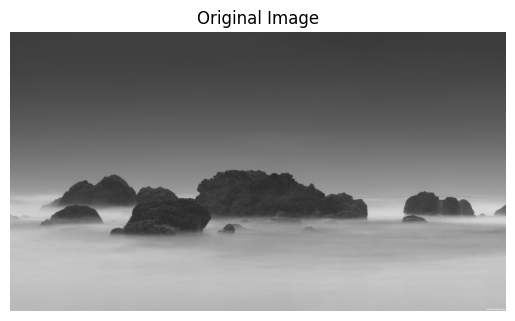

In [8]:
FILE_PATH = "image.jpg"
image = cv2.imread(FILE_PATH)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

img_height, img_width = image.shape[:2]

plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

## Pixel Transformations

### Image Translation

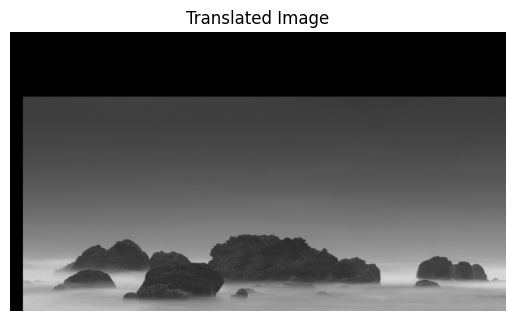

In [ ]:
TR_X    = 100       # Move 100 px right
TR_Y    = 500       # Move 500 px down

tr_mtx = np.array([
    [1, 0, TR_X],
    [0, 1, TR_Y]
], dtype=np.float32)

output_img = cv2.warpAffine(image, tr_mtx, (img_width, img_height))

plt.imshow(output_img)
plt.title("Translated Image")
plt.axis("off")
plt.show()

### Image Rotation

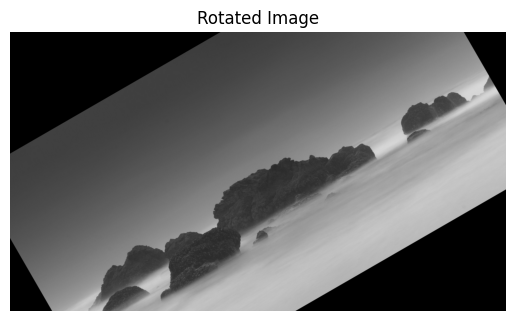

In [ ]:
ROT_ANG     = 30    # Rotate by 30 degree

center_img = np.array([
    img_width // 2,
    img_height // 2
])

ang_rad = np.deg2rad(ROT_ANG)
ca = np.cos(ang_rad)
sa = np.sin(ang_rad)

rot_mtx = np.array([
    [ ca, sa, center_img[0] * (1 - ca) - center_img[1] * sa],
    [-sa, ca, center_img[1] * (1 - ca) + center_img[0] * sa]
], dtype=np.float32)

output_img = cv2.warpAffine(image, rot_mtx, (img_width, img_height))

plt.imshow(output_img)
plt.title("Rotated Image")
plt.axis("off")
plt.show()

### Image Scaling

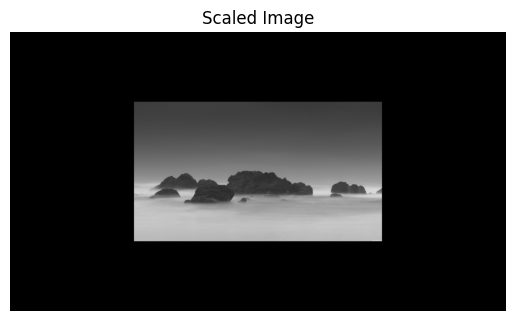

In [ ]:
SCALE_FACTOR    = 0.5

scale_mtx = np.array([
    [SCALE_FACTOR,            0, center_img[0] * (1 - SCALE_FACTOR)],
    [           0, SCALE_FACTOR, center_img[1] * (1 - SCALE_FACTOR)]
], dtype=np.float32)

output_img = cv2.warpAffine(image, scale_mtx, (img_width, img_height))

plt.imshow(output_img)
plt.title("Scaled Image")
plt.axis("off")
plt.show()

### Image Shearing

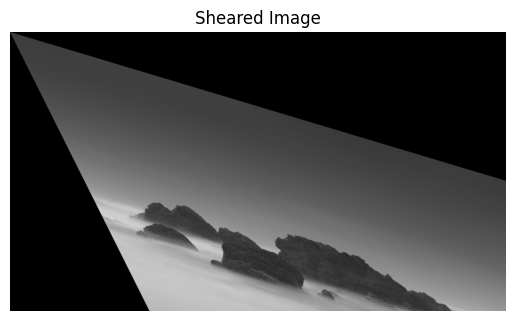

In [ ]:
VERT_SHEAR  = 0.3
HORI_SHEAR  = 0.5

shear_mtx = np.array([
    [         1, HORI_SHEAR, 0],
    [VERT_SHEAR,          1, 0]
], dtype=np.float32)

output_img = cv2.warpAffine(image, shear_mtx, (img_width, img_height))

plt.imshow(output_img)
plt.title("Sheared Image")
plt.axis("off")
plt.show()

## Spatial Transformation

### Fourier Transform

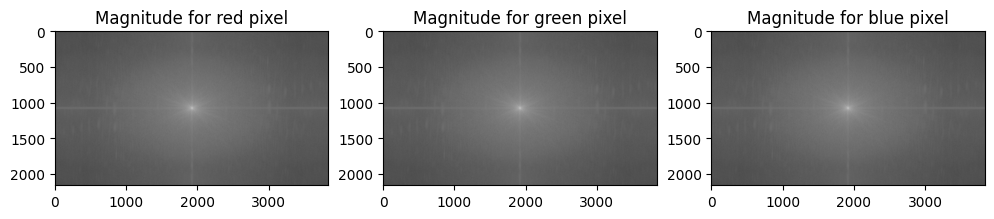

In [72]:
image_r = image[:, :, 0]
image_g = image[:, :, 1]
image_b = image[:, :, 2]

fft_r = np.fft.fft2(image_r)
shift_r = np.fft.fftshift(fft_r)
mag_r = 20 * np.log10(np.abs(shift_r))

fft_g = np.fft.fft2(image_g)
shift_g = np.fft.fftshift(fft_g)
mag_g = 20 * np.log10(np.abs(shift_g))

fft_b = np.fft.fft2(image_b)
shift_b = np.fft.fftshift(fft_b)
mag_b = 20 * np.log10(np.abs(shift_b))

plt.figure(figsize=(12, 4))

plt.subplot(131), plt.imshow(mag_r, cmap='gray'),
plt.title("Magnitude for red pixel")

plt.subplot(132), plt.imshow(mag_g, cmap='gray'),
plt.title("Magnitude for green pixel")

plt.subplot(133), plt.imshow(mag_b, cmap='gray'),
plt.title("Magnitude for blue pixel")

plt.show()


### Walsh-Hadamard Transform